In [1]:
import sys
import utils_1 as utils
from importlib import reload
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
reload(utils)

C:\Users\muham\AppData\Roaming\Python\Python38\site-packages\pandas\core\computation\expressions.py:20: UserWarning: Pandas requires version '2.7.3' or newer of 'numexpr' (version '2.7.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


<module 'utils_1' from 'D:\\(Akademik)\\(CDT in Mathematics of Random Systems)\\[AMM Implementation]\\utils_1.py'>

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import matplotlib.pylab as pylab
params = {'legend.fontsize': 'x-large',
          'figure.figsize': (8, 5),
         'axes.labelsize': 'x-large',
         'axes.titlesize':'x-large',
         'xtick.labelsize':'x-large',
         'ytick.labelsize':'x-large'}
pylab.rcParams.update(params)
%config InlineBackend.figure_format = "retina"

import matplotlib
plt.rc('text', usetex=True)
plt.rc('text.latex', preamble=r'\usepackage{amsmath,amsfonts}')

In [4]:
S0 = 100
xi = .1
tr_cost = 1e-3
fee = tr_cost * xi * S0

params_env = {'sigma': 2., 'S0': S0, 'Z0': 100., 'Y0': 100., 
              'eta': .1, 'xi': xi, 'T': 1., 'a1': 0, 'a2': 2, 'a3': 100., 'Nt': 10_000,
              'fee': fee, 'feeV': fee, 'C': 0.1, 'gamma': 1e-2, 'zeta': 1e-2, 'tempLP': 1e-2, 'P0': 1}

In [5]:
env = utils.environment(**params_env)

In [6]:
np.random.seed(100)

nsims = 1_000
strag = '1'

#S, Y, Z, X, nu, wealth, perf, rew = env.simulate_venue(nsims=nsims, strag=strag)
S, Y, Z, X, nu, wealth, perf, rew, venue_wealth, A_a_hist, A_b_hist, A_W_hist, A_B_hist, rew_drift_hist = env.simulate_venue(nsims=nsims, strag=strag, verbose = True)

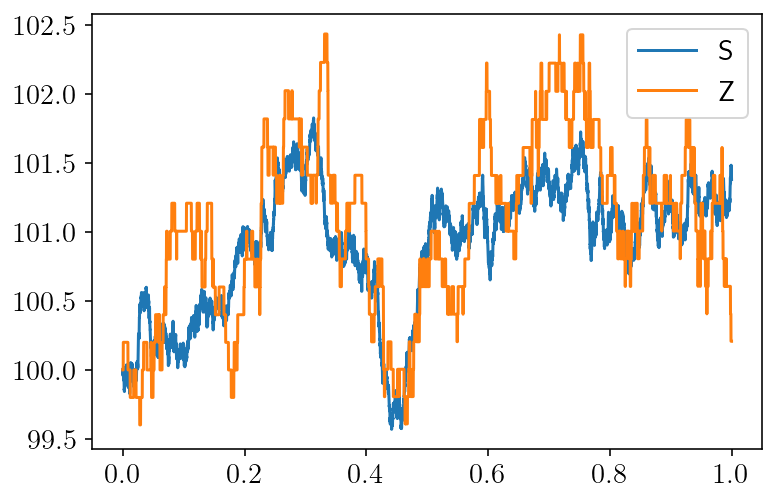

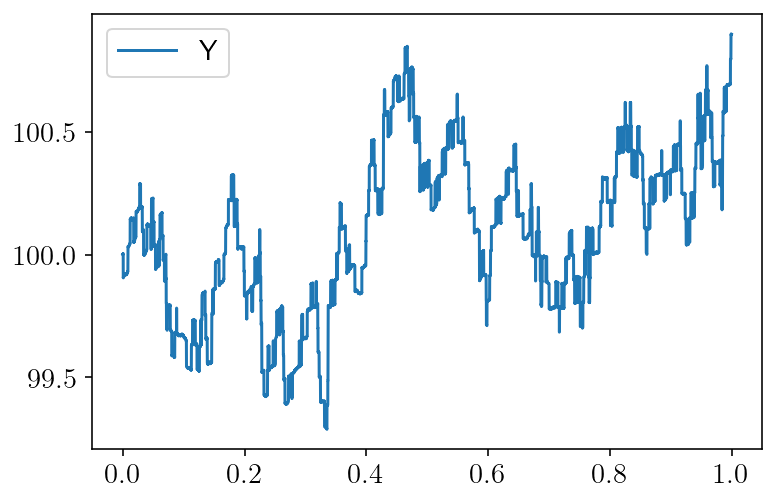

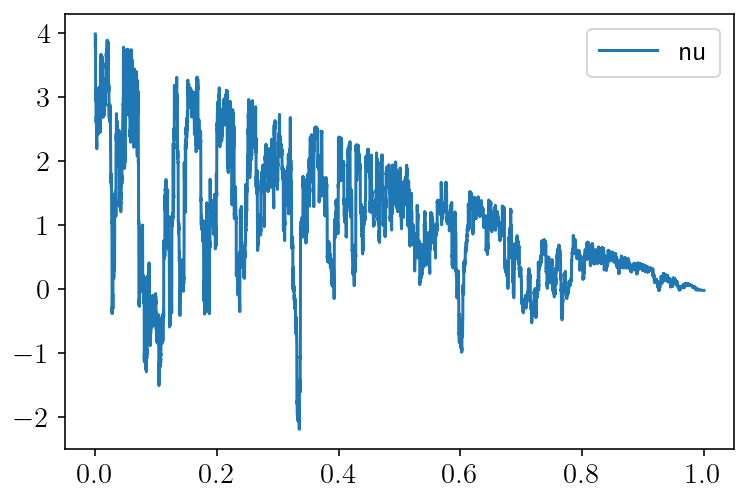

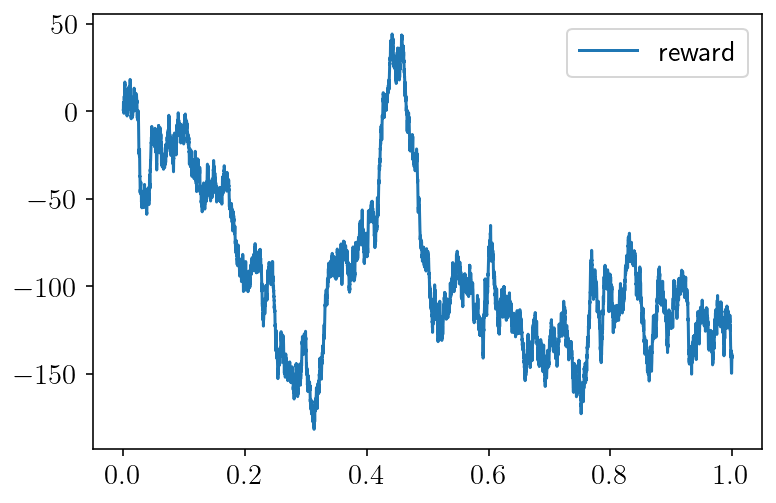

In [7]:
num_sim = 58

plt.plot(env.timesteps, S[:,num_sim], label='S')
plt.plot(env.timesteps, Z[:,num_sim], label='Z')
plt.legend()
plt.show()

plt.plot(env.timesteps, Y[:,num_sim], label='Y')
plt.legend()
plt.show()

#plt.plot(env.timesteps, Z[:,num_sim], label='Z')
#plt.legend()
#plt.show()

#plt.plot(env.timesteps, X[:,num_sim], label='X')
#plt.legend()
#plt.show()

plt.plot(env.timesteps, nu[:,num_sim], label='nu')
plt.legend()
plt.show()


plt.plot(env.timesteps, rew[:,num_sim], label='reward')
plt.legend()
plt.show()

In [16]:
rew_drift_hist[:,num_sim]

array([2.15999568, 2.15945493, 2.15236198, ..., 2.15570585, 2.1495885 ,
       2.15137847])

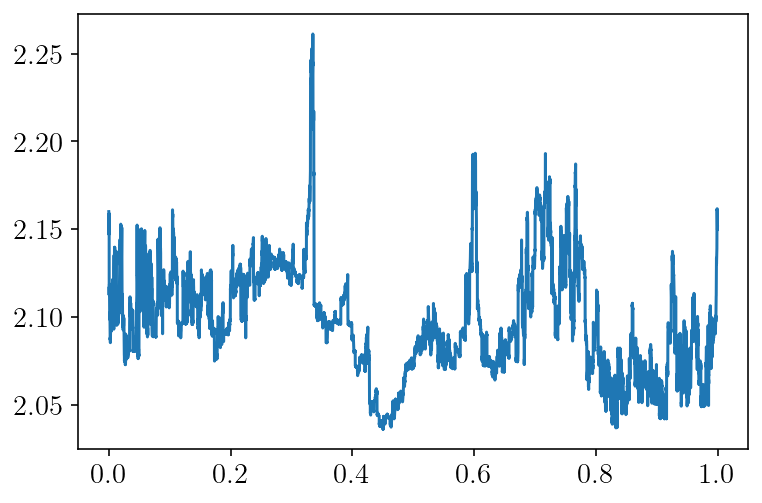

In [15]:
plt.plot(env.timesteps[:-1], rew_drift_hist[:,num_sim])

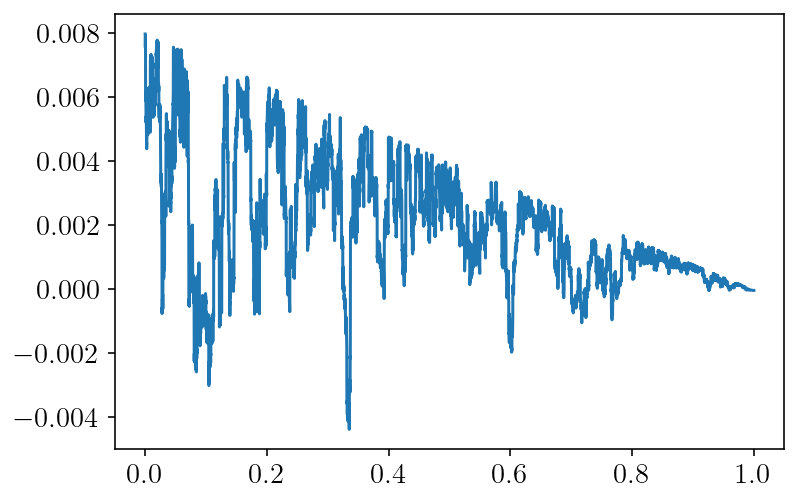

In [17]:
plt.plot(env.timesteps[:-1], A_B_hist[:,num_sim])

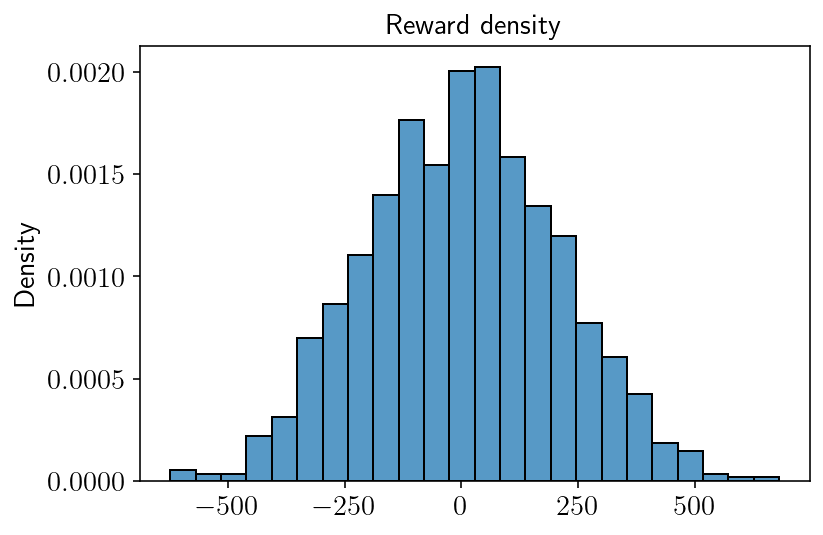

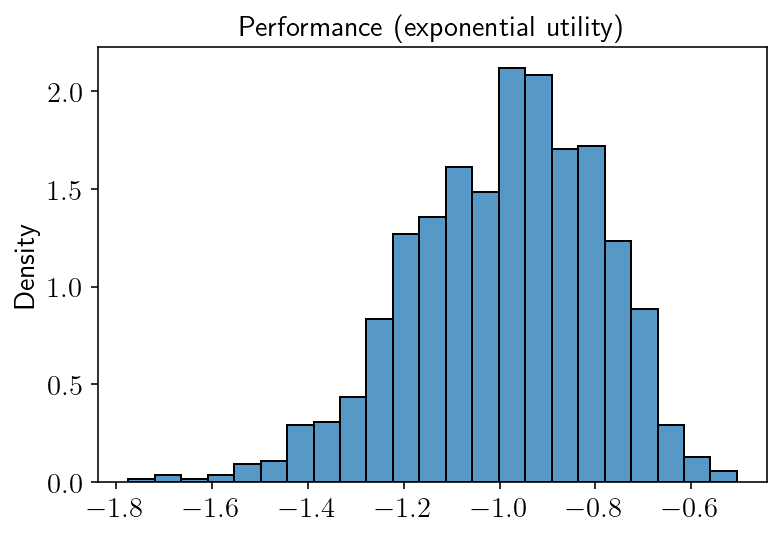

LP's expected performance (exponential utility, strag:1): -0.98979
LP's expected wealth: 2.99551
Expected reward: 2.69849


In [8]:
sns.histplot(rew[-1,:], stat='density')
plt.title("Reward density")
plt.show()

sns.histplot(perf[0,:], stat='density')
plt.title("Performance (exponential utility)")
plt.show()

print(f'LP\'s expected performance (exponential utility, strag:{strag}): {perf[0,:].mean():1.5f}')
print(f'LP\'s expected wealth: {wealth[0,:].mean():1.5f}')
print(f'Expected reward: {rew[-1,:].mean():1.5f}')

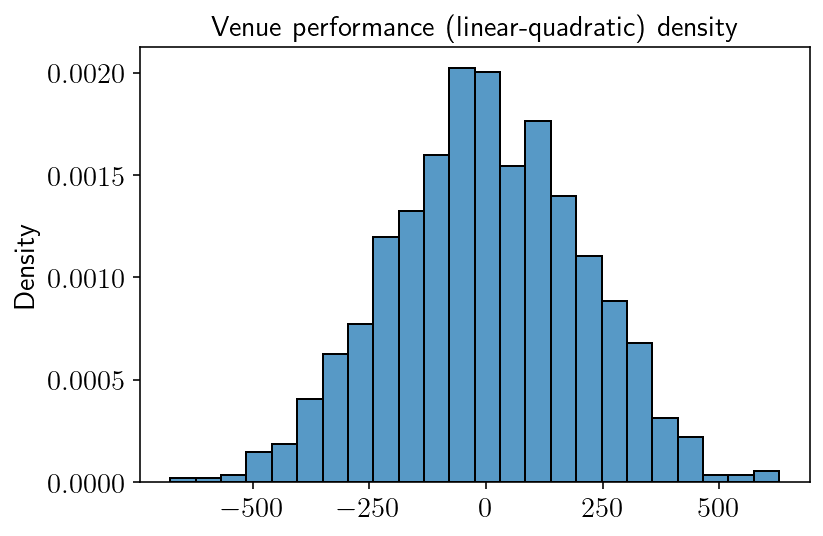

Venue's expected performance (LQ utility): 1.33894


In [9]:
sns.histplot(venue_wealth[0,:], stat='density')
plt.title("Venue performance (linear-quadratic) density")
plt.show()

print(f'Venue\'s expected performance (LQ utility): {venue_wealth[0,:].mean():1.5f}')

# LP does not trade

In [10]:
np.random.seed(100)

In [11]:
nsims = 1_000
strag = '0'

S, Y, Z, X, nu, wealth, perf, rew, venue_wealth = env.simulate_venue(nsims=nsims, strag=strag, verbose = False)

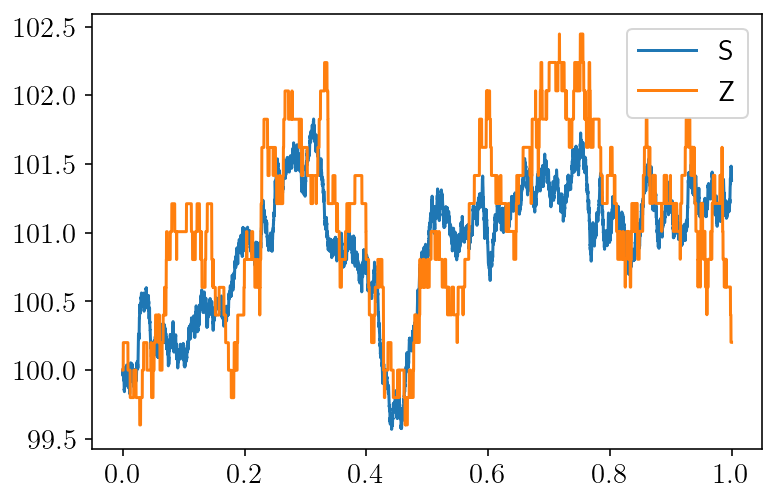

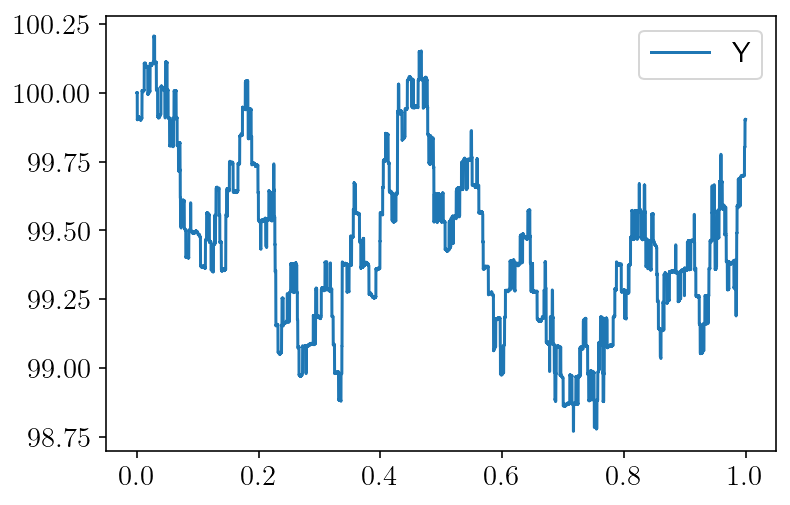

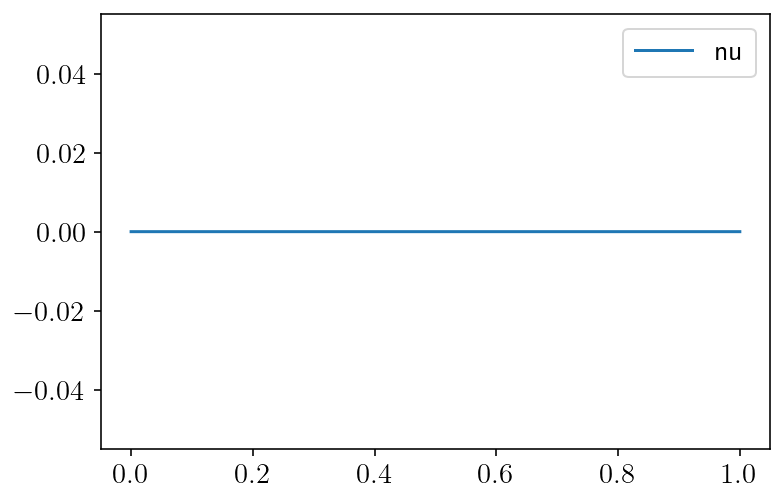

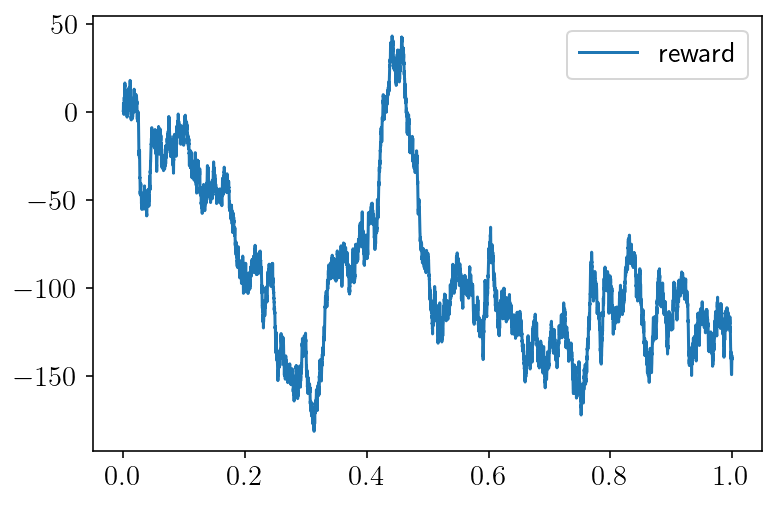

In [12]:
num_sim = 58

plt.plot(env.timesteps, S[:,num_sim], label='S')
plt.plot(env.timesteps, Z[:,num_sim], label='Z')
plt.legend()
plt.show()

plt.plot(env.timesteps, Y[:,num_sim], label='Y')
plt.legend()
plt.show()

#plt.plot(env.timesteps, Z[:,num_sim], label='Z')
#plt.legend()
#plt.show()

#plt.plot(env.timesteps, X[:,num_sim], label='X')
#plt.legend()
#plt.show()

plt.plot(env.timesteps, nu[:,num_sim], label='nu')
plt.legend()
plt.show()


plt.plot(env.timesteps, rew[:,num_sim], label='reward')
plt.legend()
plt.show()

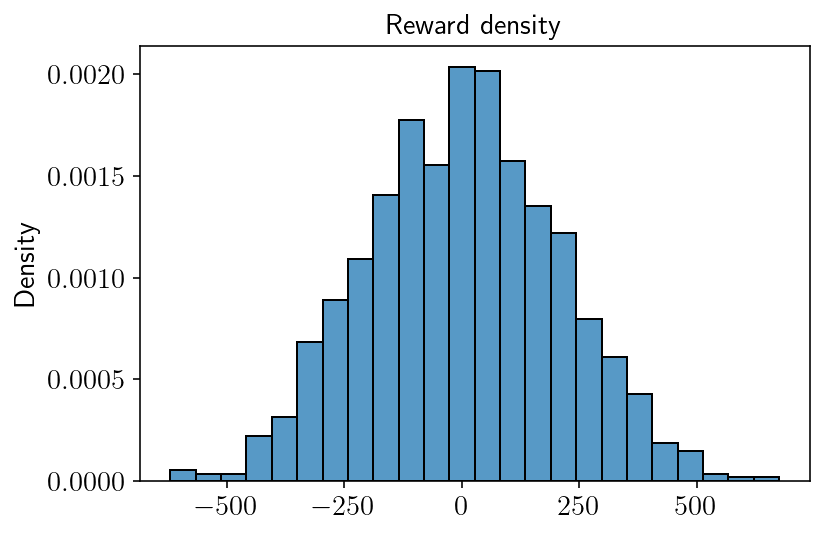

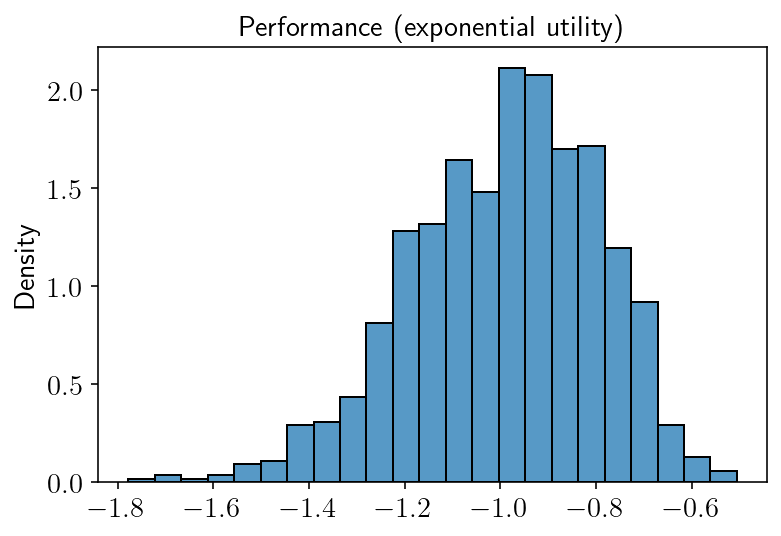

LP's expected performance (exponential utility, strag:0): -0.99080
LP's expected wealth: 2.89263
Expected reward: 2.66064


In [13]:
sns.histplot(rew[-1,:], stat='density')
plt.title("Reward density")
plt.show()

sns.histplot(perf[0,:], stat='density')
plt.title("Performance (exponential utility)")
plt.show()

print(f'LP\'s expected performance (exponential utility, strag:{strag}): {perf[0,:].mean():1.5f}')
print(f'LP\'s expected wealth: {wealth[0,:].mean():1.5f}')
print(f'Expected reward: {rew[-1,:].mean():1.5f}')

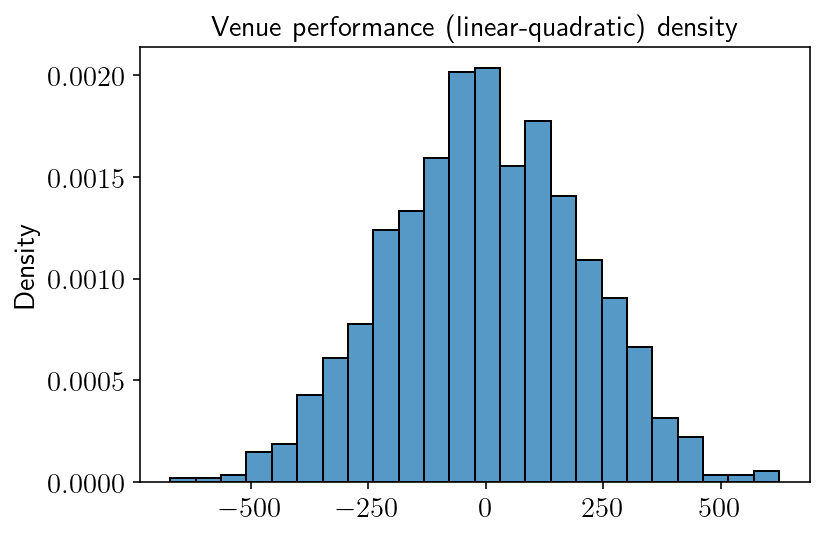

Venue's expected performance (LQ utility): 1.34876


In [14]:
sns.histplot(venue_wealth[0,:], stat='density')
plt.title("Venue performance (linear-quadratic) density")
plt.show()

print(f'Venue\'s expected performance (LQ utility): {venue_wealth[0,:].mean():1.5f}')